# Small Local Model Analysis Without Nemotron

This notebook repeats the small/local model analysis after excluding `nemotron-3-nano-4b`. It is a sensitivity notebook for checking whether prompt-factor conclusions are driven by Nemotron's unusually strong math performance.


In [1]:

from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib-cache'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)
import json, re, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p/'smallmodels').exists() and (p/'apimodels').exists() and (p/'prompt_templates').exists():
            return p.resolve()
    raise FileNotFoundError('results_analysis root not found')

ROOT = find_root()
print('Using', ROOT)

def read_jsonl(path):
    rows = []
    with path.open(encoding='utf-8') as f:
        for line_no, line in enumerate(f, 1):
            if line.strip():
                row = json.loads(line)
                row['_source_file'] = path.name
                row['_line_no'] = line_no
                rows.append(row)
    return rows

def pct_series(s):
    return (100*s).round(1).astype(str) + '%'

def hbar(df, x, y, title, fmt='{:.1%}', color='#3f7fbf', height_per_row=.38, xline=None):
    if df.empty:
        print('No rows')
        return
    fig_h = max(2.4, len(df) * height_per_row)
    fig, ax = plt.subplots(figsize=(9.5, fig_h))
    sns.barplot(data=df, x=x, y=y, ax=ax, color=color)
    if xline is not None:
        ax.axvline(xline, color='0.25', lw=1)
    ax.set_title(title, loc='left', weight='bold')
    ax.set_xlabel(x)
    ax.set_ylabel('')
    xmin, xmax = ax.get_xlim()
    span = xmax - xmin
    for patch, value in zip(ax.patches, df[x]):
        y0 = patch.get_y() + patch.get_height()/2
        if value < 0:
            ax.text(value + span*.015, y0, fmt.format(value), va='center', ha='left', color='white' if abs(value) > span*.08 else 'black', fontsize=9)
        else:
            ax.text(value + span*.015, y0, fmt.format(value), va='center', ha='left', fontsize=9)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

# Load prompt metadata.
templates = {
    'code': pd.read_csv(ROOT/'prompt_templates/prompt_matrix_prompt_template.09.csv'),
    'math': pd.read_csv(ROOT/'prompt_templates/prompt_matrix_prompt_template.09.math.csv'),
}
meta = []
for kind, t in templates.items():
    tmp = t.rename(columns={'ID':'variant_id', 'Tone':'tone', 'Role framing':'role_framing', 'Format':'format'})[['variant_id','tone','role_framing','format']].copy()
    tmp['kind'] = kind
    tmp['variant_id'] = tmp['variant_id'].astype(str)
    tmp['role_binary'] = np.where(tmp['role_framing'].str.lower().eq('no role'), 'no role', 'role')
    meta.append(tmp)
meta = pd.concat(meta, ignore_index=True)

rows = []
for path in sorted((ROOT/'smallmodels').glob('*.jsonl')):
    kind = 'math' if path.name.endswith('.math.jsonl') else 'code'
    model = path.name.replace('.math.jsonl','').replace('.jsonl','')
    for row in read_jsonl(path):
        task_id = str(row.get('task_id'))
        m = re.search(r'_(\d+)$', task_id)
        row['variant_id'] = m.group(1) if m else str(row.get('category_id', ''))
        row['base_task_id'] = re.sub(r'_\d+$', '', task_id)
        row['task_key'] = row['base_task_id'] + '::' + row['variant_id']
        row['kind'] = kind
        row['model_slug'] = model
        rows.append(row)

df = pd.DataFrame(rows).merge(meta, on=['kind','variant_id'], how='left')
for col in ['duration_seconds','prompt_tokens','completion_tokens']:
    df[col] = pd.to_numeric(df.get(col), errors='coerce').fillna(0)
df['passed'] = df['passed'].astype(bool)
df['empty_response'] = df['response_text'].fillna('').astype(str).str.strip().eq('')
df['model_short'] = df['model_slug'].str.replace('_1_50','', regex=False)
print(f'Rows: {len(df):,}; files: {df._source_file.nunique()}; models: {df.model_slug.nunique()}')


Using /Users/macos/LearningSpace/ue-courses/Thesis/02ScalingPhrase/results_analysis
Rows: 10,800; files: 12; models: 6


In [2]:

# Sensitivity filter: remove Nemotron before all downstream analyses.
original_rows = len(df)
original_models = sorted(df.model_short.unique())
df = df[~df.model_short.str.contains('nemotron', case=False, na=False)].copy()
print(f'Removed Nemotron rows: {original_rows - len(df):,}')
print(f'Remaining rows: {len(df):,}')
print('Remaining models:', ', '.join(sorted(df.model_short.unique())))


Removed Nemotron rows: 1,800
Remaining rows: 9,000
Remaining models: deepseek-coder-6.7b-instruct, gemma2-9b, llama3.1-8b, mistral-7b-instruct, qwen2.5-7b


## 0. Auto-Generated Key Insights

In [3]:

insights = []
overall = df.groupby('kind').agg(n=('passed','size'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), mean_completion_tokens=('completion_tokens','mean')).reset_index()
for _, r in overall.sort_values('pass_rate', ascending=False).iterrows():
    insights.append(f"**{r.kind}**: {r.pass_rate:.1%} pass rate across {int(r.n):,} runs; median duration {r.median_duration:.2f}s; mean completion tokens {r.mean_completion_tokens:.0f}.")

mk = df.groupby(['kind','model_short']).agg(pass_rate=('passed','mean'), mean_completion_tokens=('completion_tokens','mean'), median_duration=('duration_seconds','median')).reset_index()
for kind_name, sub in mk.groupby('kind'):
    best = sub.sort_values('pass_rate', ascending=False).iloc[0]
    worst = sub.sort_values('pass_rate', ascending=True).iloc[0]
    insights.append(f"For **{kind_name}**, model ability dominates: **{best.model_short}** is highest at {best.pass_rate:.1%}, while **{worst.model_short}** is lowest at {worst.pass_rate:.1%}.")

insights.append(f"This notebook already excludes Nemotron; remaining models are: {', '.join(sorted(df.model_short.unique()))}.")

import math as _math
import numpy as _np
from scipy.stats import ttest_ind, mannwhitneyu

def _raw_two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / _math.sqrt(var)
    return _math.erfc(z / _math.sqrt(2))

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
deltas = []
for kind_name, sub in df.groupby('kind'):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in sub.groupby(factor):
            if level == baseline:
                continue
            p_value = _raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            try:
                _, comp_p = ttest_ind(base.completion_tokens.dropna(), items.completion_tokens.dropna(), equal_var=False)
            except Exception:
                comp_p = 1.0
            try:
                _, dur_p = mannwhitneyu(base.duration_seconds.dropna(), items.duration_seconds.dropna(), alternative='two-sided')
            except Exception:
                dur_p = 1.0
            deltas.append({
                'kind': kind_name, 'factor': factor, 'level': level,
                'delta_pp': 100*(items.passed.mean()-base.passed.mean()),
                'completion_delta': items.completion_tokens.mean()-base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.median()-base.duration_seconds.median(),
                'p_value': p_value, 'completion_p': comp_p, 'duration_p': dur_p,
            })
deltas = pd.DataFrame(deltas)
if not deltas.empty:
    display(deltas.sort_values(['kind','factor','level']).reset_index(drop=True))
    strongest = deltas.iloc[deltas.delta_pp.abs().argmax()]
    insights.append(f"The largest raw prompt-factor shift is **{{strongest.kind}} / {{strongest.factor}}={{strongest.level}}** versus baseline: {{strongest.delta_pp:+.1f}} pp pass rate, p={{strongest.p_value:.4f}}, {{strongest.completion_delta:+.0f}} completion tokens (p={{strongest.completion_p:.4f}}), {{strongest.duration_delta:+.2f}}s median duration (p={{strongest.duration_p:.4f}}).")

empty = int(df.empty_response.sum())
if empty:
    by_empty = df[df.empty_response].groupby(['kind','model_short']).size().sort_values(ascending=False).head(3)
    details = '; '.join([f"{k[0]}/{k[1]}={v}" for k,v in by_empty.items()])
    insights.append(f"Data-quality warning: {empty} empty responses remain ({details}); keep this caveat near any small-model result discussion.")
else:
    insights.append("No empty responses were found in the small-model result files.")

corr = df[['passed','completion_tokens','duration_seconds']].assign(passed=df.passed.astype(float)).corr(numeric_only=True)
insights.append(f"Efficiency is part of the result: completion-token/pass correlation is {corr.loc['completion_tokens','passed']:+.2f}, and duration/pass correlation is {corr.loc['duration_seconds','passed']:+.2f} across all small-model runs.")

display(Markdown('\n'.join(f'- {x}' for x in insights)))


,kind,factor,level,delta_pp,completion_delta,duration_delta,p_value,completion_p,duration_p
0,code,format,json,0.066667,-13.912000,-0.400649,0.940099,3.537029e-02,1.408621e-02
1,code,format,xml,0.266667,-12.476667,-0.531224,0.765412,6.913414e-02,1.264290e-02
2,code,role_binary,role,-0.933333,8.782667,0.190293,0.200152,1.108159e-01,3.865398e-02
3,code,tone,aggressive,-0.066667,-1.895333,-0.028552,0.941243,7.795474e-01,7.837627e-01
4,code,tone,polite,-0.600000,49.464667,1.588619,0.498848,1.637567e-13,8.083985e-23
5,math,format,json,-5.266667,-36.221333,-0.037739,0.000239,2.649614e-06,2.033358e-02
6,math,format,xml,-2.533333,1.838667,0.021398,0.085128,8.424305e-01,2.096533e-01
7,math,role_binary,role,2.400000,12.049778,0.054392,0.040442,8.123934e-02,1.764738e-03
8,math,tone,aggressive,1.266667,8.781333,0.142668,0.371662,2.898200e-01,5.553014e-11
9,math,tone,polite,2.333333,20.306000,0.095941,0.103571,1.375513e-02,2.500763e-08


- **math**: 19.1% pass rate across 4,500 runs; median duration 0.99s; mean completion tokens 130.
- **code**: 6.4% pass rate across 4,500 runs; median duration 8.74s; mean completion tokens 348.
- For **code**, model ability dominates: **qwen2.5-7b** is highest at 13.2%, while **mistral-7b-instruct** is lowest at 0.4%.
- For **math**, model ability dominates: **llama3.1-8b** is highest at 43.2%, while **deepseek-coder-6.7b-instruct** is lowest at 5.7%.
- This notebook already excludes Nemotron; remaining models are: deepseek-coder-6.7b-instruct, gemma2-9b, llama3.1-8b, mistral-7b-instruct, qwen2.5-7b.
- The largest raw prompt-factor shift is **{strongest.kind} / {strongest.factor}={strongest.level}** versus baseline: {strongest.delta_pp:+.1f} pp pass rate, p={strongest.p_value:.4f}, {strongest.completion_delta:+.0f} completion tokens (p={strongest.completion_p:.4f}), {strongest.duration_delta:+.2f}s median duration (p={strongest.duration_p:.4f}).
- No empty responses were found in the small-model result files.
- Efficiency is part of the result: completion-token/pass correlation is -0.16, and duration/pass correlation is -0.12 across all small-model runs.

## 1. Integrity

In [4]:

integrity = (df.groupby('_source_file')
    .agg(rows=('task_key','size'), unique_task_keys=('task_key','nunique'), empty_responses=('empty_response','sum'), passed=('passed','sum'))
    .assign(duplicates=lambda x: x['rows']-x['unique_task_keys'])
    .reset_index()
    .sort_values('_source_file'))
display(integrity[[' _source_file'.strip(), 'rows', 'unique_task_keys', 'duplicates', 'empty_responses', 'passed']])


,_source_file,rows,unique_task_keys,duplicates,empty_responses,passed
0,deepseek-coder-6.7b-instruct_1_50.jsonl,900,900,0,0,10
1,deepseek-coder-6.7b-instruct_1_50.math.jsonl,900,900,0,0,51
2,gemma2-9b_1_50.jsonl,900,900,0,0,102
3,gemma2-9b_1_50.math.jsonl,900,900,0,0,137
4,llama3.1-8b_1_50.jsonl,900,900,0,0,52
5,llama3.1-8b_1_50.math.jsonl,900,900,0,0,389
6,mistral-7b-instruct_1_50.jsonl,900,900,0,0,4
7,mistral-7b-instruct_1_50.math.jsonl,900,900,0,0,69
8,qwen2.5-7b_1_50.jsonl,900,900,0,0,119
9,qwen2.5-7b_1_50.math.jsonl,900,900,0,0,212


## 2. Pass Rate By Kind And Model

,kind,n,passed,pass_rate,median_duration,empty_rate,pass_rate_pct,empty_rate_pct
0,code,4500,287,0.063778,8.743776,0.0,6.4%,0.0%
1,math,4500,858,0.190667,0.987497,0.0,19.1%,0.0%


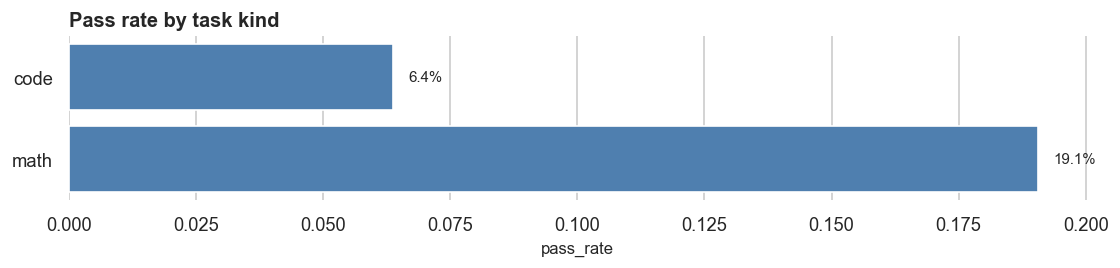

,kind,model_short,n,passed,pass_rate,median_duration,empty_rate,label
4,code,qwen2.5-7b,900,119,0.132222,8.754345,0.0,code / qwen2.5-7b
1,code,gemma2-9b,900,102,0.113333,5.524169,0.0,code / gemma2-9b
2,code,llama3.1-8b,900,52,0.057778,11.161960,0.0,code / llama3.1-8b
0,code,deepseek-coder-6.7b-instruct,900,10,0.011111,9.041468,0.0,code / deepseek-coder-6.7b-instruct
3,code,mistral-7b-instruct,900,4,0.004444,9.120987,0.0,code / mistral-7b-instruct
7,math,llama3.1-8b,900,389,0.432222,5.085117,0.0,math / llama3.1-8b
9,math,qwen2.5-7b,900,212,0.235556,0.678500,0.0,math / qwen2.5-7b
6,math,gemma2-9b,900,137,0.152222,0.801960,0.0,math / gemma2-9b
8,math,mistral-7b-instruct,900,69,0.076667,0.888790,0.0,math / mistral-7b-instruct
5,math,deepseek-coder-6.7b-instruct,900,51,0.056667,5.348068,0.0,math / deepseek-coder-6.7b-instruct


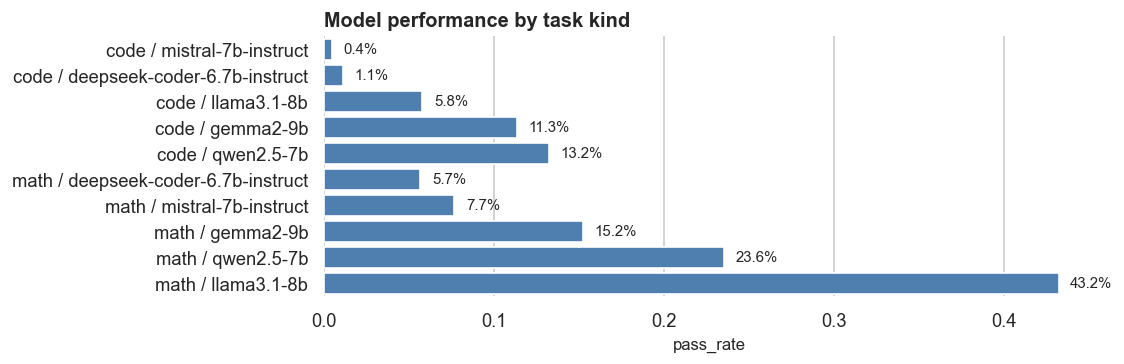

In [5]:

kind = df.groupby('kind').agg(n=('passed','size'), passed=('passed','sum'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), empty_rate=('empty_response','mean')).reset_index()
display(kind.assign(pass_rate_pct=pct_series(kind.pass_rate), empty_rate_pct=pct_series(kind.empty_rate)))
hbar(kind.sort_values('pass_rate'), 'pass_rate', 'kind', 'Pass rate by task kind')

mk = df.groupby(['kind','model_short']).agg(n=('passed','size'), passed=('passed','sum'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), empty_rate=('empty_response','mean')).reset_index()
mk['label'] = mk['kind'] + ' / ' + mk['model_short']
display(mk.sort_values(['kind','pass_rate'], ascending=[True,False]))
hbar(mk.sort_values(['kind','pass_rate'], ascending=[True,True]), 'pass_rate', 'label', 'Model performance by task kind', height_per_row=.32)


## 3. Duration And Tokens

,kind,model_short,pass_rate,median_duration,mean_duration,mean_prompt_tokens,mean_completion_tokens,label
0,code,deepseek-coder-6.7b-instruct,0.011111,9.041468,9.725046,313.031111,491.086667,code / deepseek-coder-6.7b-instruct
2,code,llama3.1-8b,0.057778,11.161960,11.639695,268.660000,393.932222,code / llama3.1-8b
3,code,mistral-7b-instruct,0.004444,9.120987,9.585696,301.911111,366.226667,code / mistral-7b-instruct
4,code,qwen2.5-7b,0.132222,8.754345,9.197864,282.540000,315.995556,code / qwen2.5-7b
1,code,gemma2-9b,0.113333,5.524169,6.230322,289.346667,175.217778,code / gemma2-9b
5,math,deepseek-coder-6.7b-instruct,0.056667,5.348068,5.884696,174.184444,287.058889,math / deepseek-coder-6.7b-instruct
7,math,llama3.1-8b,0.432222,5.085117,8.436519,157.493333,273.568889,math / llama3.1-8b
8,math,mistral-7b-instruct,0.076667,0.888790,2.326470,167.397778,78.651111,math / mistral-7b-instruct
6,math,gemma2-9b,0.152222,0.801960,0.826426,159.860000,6.101111,math / gemma2-9b
9,math,qwen2.5-7b,0.235556,0.678500,0.729726,158.293333,5.555556,math / qwen2.5-7b


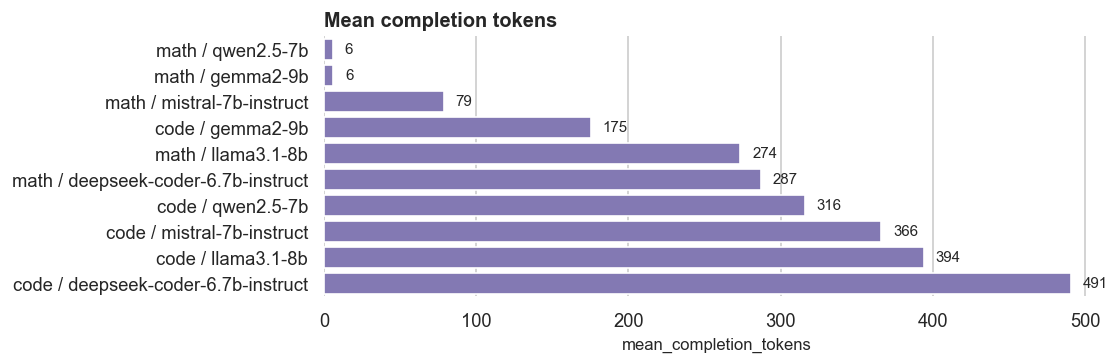

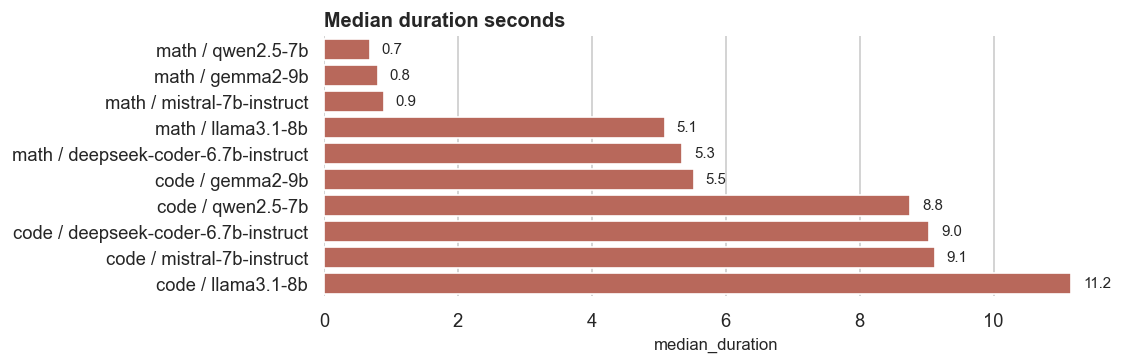

In [6]:

behavior = df.groupby(['kind','model_short']).agg(
    pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), mean_duration=('duration_seconds','mean'),
    mean_prompt_tokens=('prompt_tokens','mean'), mean_completion_tokens=('completion_tokens','mean')
).reset_index()
behavior['label'] = behavior['kind'] + ' / ' + behavior['model_short']
display(behavior.sort_values(['kind','mean_completion_tokens'], ascending=[True,False]))
hbar(behavior.sort_values('mean_completion_tokens'), 'mean_completion_tokens', 'label', 'Mean completion tokens', fmt='{:.0f}', color='#7c6fbd', height_per_row=.32)
hbar(behavior.sort_values('median_duration'), 'median_duration', 'label', 'Median duration seconds', fmt='{:.1f}', color='#c75d4c', height_per_row=.32)


## 4. Prompt Factor Deltas

,kind,factor,level,baseline,baseline_n,n,baseline_pass_rate,pass_rate,delta_pass_rate_pp,p_value,delta_completion_tokens,delta_duration_seconds,label
3,code,format,json,plaintext,1500,1500,0.062667,0.063333,0.066667,0.940099,-13.912000,-0.325598,code / format=json
4,code,format,xml,plaintext,1500,1500,0.062667,0.065333,0.266667,0.765412,-12.476667,-0.281672,code / format=xml
2,code,role_binary,role,no role,2250,2250,0.068444,0.059111,-0.933333,0.200152,8.782667,0.218898,code / role_binary=role
0,code,tone,aggressive,neutral,1500,1500,0.066000,0.065333,-0.066667,0.941243,-1.895333,0.008335,code / tone=aggressive
1,code,tone,polite,neutral,1500,1500,0.066000,0.060000,-0.600000,0.498848,49.464667,1.313774,code / tone=polite
8,math,format,json,plaintext,1500,1500,0.216667,0.164000,-5.266667,0.000239,-36.221333,-1.076805,math / format=json
9,math,format,xml,plaintext,1500,1500,0.216667,0.191333,-2.533333,0.085128,1.838667,-0.026871,math / format=xml
7,math,role_binary,role,no role,2250,2250,0.178667,0.202667,2.400000,0.040442,12.049778,0.336241,math / role_binary=role
5,math,tone,aggressive,neutral,1500,1500,0.178667,0.191333,1.266667,0.371662,8.781333,0.343971,math / tone=aggressive
6,math,tone,polite,neutral,1500,1500,0.178667,0.202000,2.333333,0.103571,20.306000,0.661217,math / tone=polite


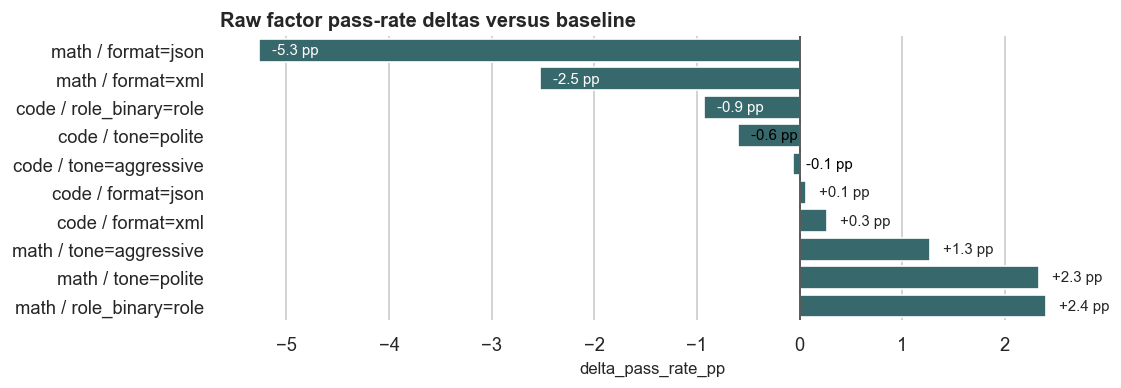

In [7]:

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}

def raw_two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / math.sqrt(var)
    return math.erfc(z / math.sqrt(2))

records = []
for kind_name, sub in df.groupby('kind'):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        for level, items in sub.groupby(factor):
            if level == baseline or base.empty:
                continue
            p_value = raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            records.append({
                'kind': kind_name, 'factor': factor, 'level': level, 'baseline': baseline,
                'baseline_n': len(base), 'n': len(items),
                'baseline_pass_rate': base.passed.mean(), 'pass_rate': items.passed.mean(),
                'delta_pass_rate_pp': 100*(items.passed.mean() - base.passed.mean()),
                'p_value': p_value,
                'delta_completion_tokens': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'delta_duration_seconds': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
contrasts = pd.DataFrame(records)
contrasts['label'] = contrasts['kind'] + ' / ' + contrasts['factor'] + '=' + contrasts['level']
display(contrasts.sort_values(['kind','factor','level']))
hbar(contrasts.sort_values('delta_pass_rate_pp'), 'delta_pass_rate_pp', 'label', 'Raw factor pass-rate deltas versus baseline', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.34)


## 5. Known Empty Responses

In [8]:

issues = df[df.empty_response].groupby(['kind','model_short']).agg(empty_responses=('task_id','size'), example_task_ids=('task_id', lambda s: ', '.join(s.head(12)))).reset_index()
display(issues if not issues.empty else pd.DataFrame({'status':['No empty responses found']}))


,status
0,No empty responses found


## 6. Paired Prompt-Factor Contrasts

,kind,factor,baseline,level,paired_units,mean_pass_delta_pp,positive_units,negative_units,mean_completion_delta,mean_duration_delta,label
0,code,format,plaintext,json,250,0.066667,21,19,-13.912000,-0.325598,code / format=json
1,code,format,plaintext,xml,250,0.266667,23,12,-12.476667,-0.281672,code / format=xml
2,code,role_binary,no role,role,250,-0.933333,19,27,8.782667,0.218898,code / role_binary=role
3,code,tone,neutral,aggressive,250,-0.066667,19,22,-1.895333,0.008335,code / tone=aggressive
4,code,tone,neutral,polite,250,-0.600000,20,18,49.464667,1.313774,code / tone=polite
5,math,format,plaintext,json,250,-5.266667,25,62,-36.221333,-1.076805,math / format=json
6,math,format,plaintext,xml,250,-2.533333,28,52,1.838667,-0.026871,math / format=xml
7,math,role_binary,no role,role,250,2.400000,52,34,12.049778,0.336241,math / role_binary=role
8,math,tone,neutral,aggressive,250,1.266667,41,29,8.781333,0.343971,math / tone=aggressive
9,math,tone,neutral,polite,250,2.333333,46,25,20.306000,0.661217,math / tone=polite


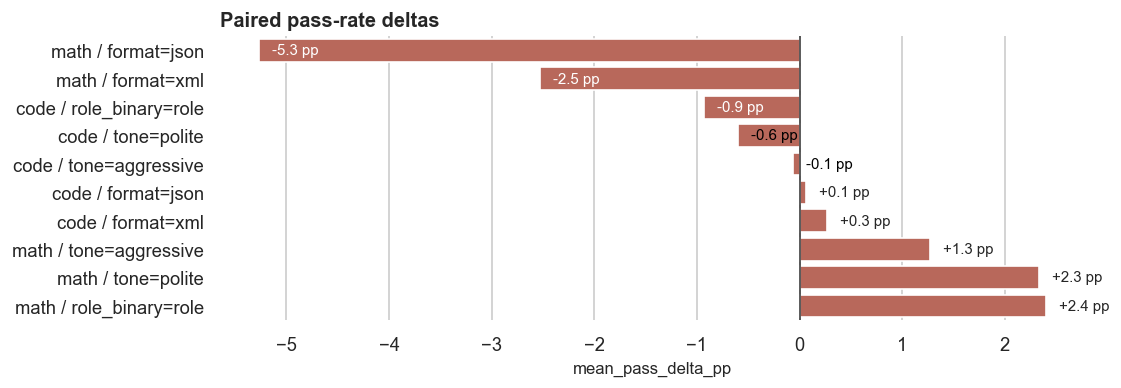

In [9]:

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
paired_records = []
for (kind_name, model, base_task), unit in df.groupby(['kind','model_short','base_task_id']):
    for factor, baseline in baselines.items():
        base = unit[unit[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in unit.groupby(factor):
            if level == baseline:
                continue
            paired_records.append({
                'kind': kind_name, 'model_short': model, 'base_task_id': base_task,
                'factor': factor, 'baseline': baseline, 'level': level,
                'pass_delta': items.passed.mean() - base.passed.mean(),
                'completion_delta': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
paired_unit = pd.DataFrame(paired_records)
paired = (paired_unit.groupby(['kind','factor','baseline','level'])
    .agg(paired_units=('pass_delta','size'), mean_pass_delta_pp=('pass_delta', lambda s: 100*s.mean()),
         positive_units=('pass_delta', lambda s: int((s>0).sum())), negative_units=('pass_delta', lambda s: int((s<0).sum())),
         mean_completion_delta=('completion_delta','mean'), mean_duration_delta=('duration_delta','mean'))
    .reset_index())
paired['label'] = paired['kind'] + ' / ' + paired['factor'] + '=' + paired['level']
display(paired.sort_values(['kind','factor','level']))
hbar(paired.sort_values('mean_pass_delta_pp'), 'mean_pass_delta_pp', 'label', 'Paired pass-rate deltas', fmt='{:+.1f} pp', color='#c75d4c', xline=0, height_per_row=.34)


## 7. Model-Specific Heterogeneity

,kind,factor,level,min_delta_pp,max_delta_pp,mean_delta_pp,range_delta_pp,label
5,math,format,json,-15.666667,0.000000,-5.266667,15.666667,math / format=json
6,math,format,xml,-9.666667,5.666667,-2.533333,15.333333,math / format=xml
7,math,role_binary,role,-0.666667,10.222222,2.400000,10.888889,math / role_binary=role
9,math,tone,polite,-0.333333,5.333333,2.333333,5.666667,math / tone=polite
3,code,tone,aggressive,-2.000000,2.000000,-0.066667,4.000000,code / tone=aggressive
4,code,tone,polite,-2.666667,0.333333,-0.600000,3.000000,code / tone=polite
8,math,tone,aggressive,-0.666667,2.333333,1.266667,3.000000,math / tone=aggressive
2,code,role_binary,role,-2.222222,0.444444,-0.933333,2.666667,code / role_binary=role
0,code,format,json,-1.000000,1.000000,0.066667,2.000000,code / format=json
1,code,format,xml,0.000000,0.666667,0.266667,0.666667,code / format=xml


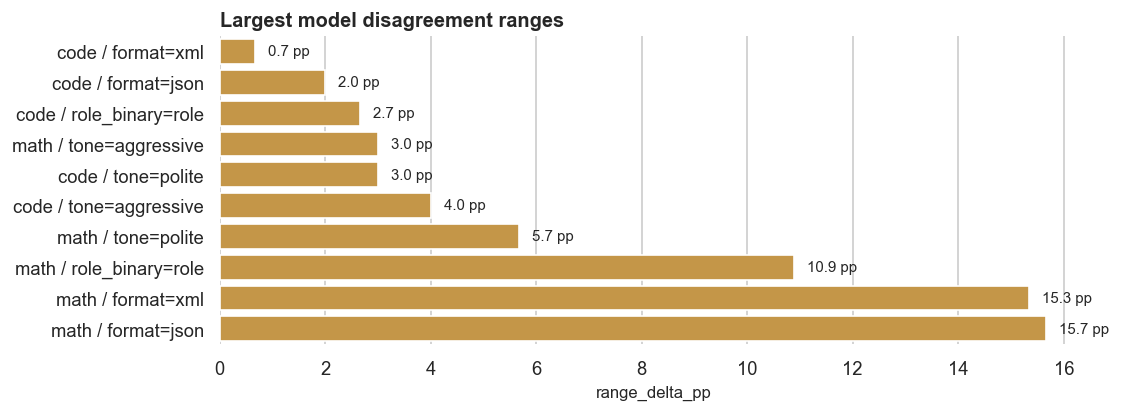

,kind,model_short,factor,level,delta_pp,n
3,code,deepseek-coder-6.7b-instruct,format,json,1.000000,300
23,code,qwen2.5-7b,format,json,0.666667,300
18,code,mistral-7b-instruct,format,json,0.000000,300
13,code,llama3.1-8b,format,json,-0.333333,300
8,code,gemma2-9b,format,json,-1.000000,300
14,code,llama3.1-8b,format,xml,0.666667,300
19,code,mistral-7b-instruct,format,xml,0.333333,300
4,code,deepseek-coder-6.7b-instruct,format,xml,0.333333,300
9,code,gemma2-9b,format,xml,0.000000,300
24,code,qwen2.5-7b,format,xml,0.000000,300


In [10]:

model_contrasts = []
for (kind_name, model), sub in df.groupby(['kind','model_short']):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in sub.groupby(factor):
            if level == baseline:
                continue
            model_contrasts.append({'kind':kind_name, 'model_short':model, 'factor':factor, 'level':level, 'delta_pp':100*(items.passed.mean()-base.passed.mean()), 'n':len(items)})
model_contrasts = pd.DataFrame(model_contrasts)
hetero = (model_contrasts.groupby(['kind','factor','level'])
    .agg(min_delta_pp=('delta_pp','min'), max_delta_pp=('delta_pp','max'), mean_delta_pp=('delta_pp','mean'))
    .assign(range_delta_pp=lambda x: x.max_delta_pp - x.min_delta_pp)
    .reset_index().sort_values('range_delta_pp', ascending=False))
hetero['label'] = hetero['kind'] + ' / ' + hetero['factor'] + '=' + hetero['level']
display(hetero)
hbar(hetero.head(12).sort_values('range_delta_pp'), 'range_delta_pp', 'label', 'Largest model disagreement ranges', fmt='{:.1f} pp', color='#d89b34', height_per_row=.36)
display(model_contrasts.sort_values(['kind','factor','level','delta_pp'], ascending=[True,True,True,False]).head(30))


## 8. Math-Versus-Code Factor Differences

kind,model_short,factor,level,code_delta_pp,math_delta_pp,math_minus_code_delta_pp,label
10,llama3.1-8b,format,json,-0.333333,-15.666667,-15.333333,llama3.1-8b / format=json
22,qwen2.5-7b,role_binary,role,-1.111111,10.222222,11.333333,qwen2.5-7b / role_binary=role
11,llama3.1-8b,format,xml,0.666667,-9.666667,-10.333333,llama3.1-8b / format=xml
14,llama3.1-8b,tone,polite,-2.666667,5.333333,8.000000,llama3.1-8b / tone=polite
1,deepseek-coder-6.7b-instruct,format,xml,0.333333,-5.666667,-6.000000,deepseek-coder-6.7b-instruct / format=xml
21,qwen2.5-7b,format,xml,0.000000,5.666667,5.666667,qwen2.5-7b / format=xml
0,deepseek-coder-6.7b-instruct,format,json,1.000000,-4.333333,-5.333333,deepseek-coder-6.7b-instruct / format=json
4,deepseek-coder-6.7b-instruct,tone,polite,0.333333,4.666667,4.333333,deepseek-coder-6.7b-instruct / tone=polite
5,gemma2-9b,format,json,-1.000000,-5.333333,-4.333333,gemma2-9b / format=json
8,gemma2-9b,tone,aggressive,-2.000000,2.333333,4.333333,gemma2-9b / tone=aggressive


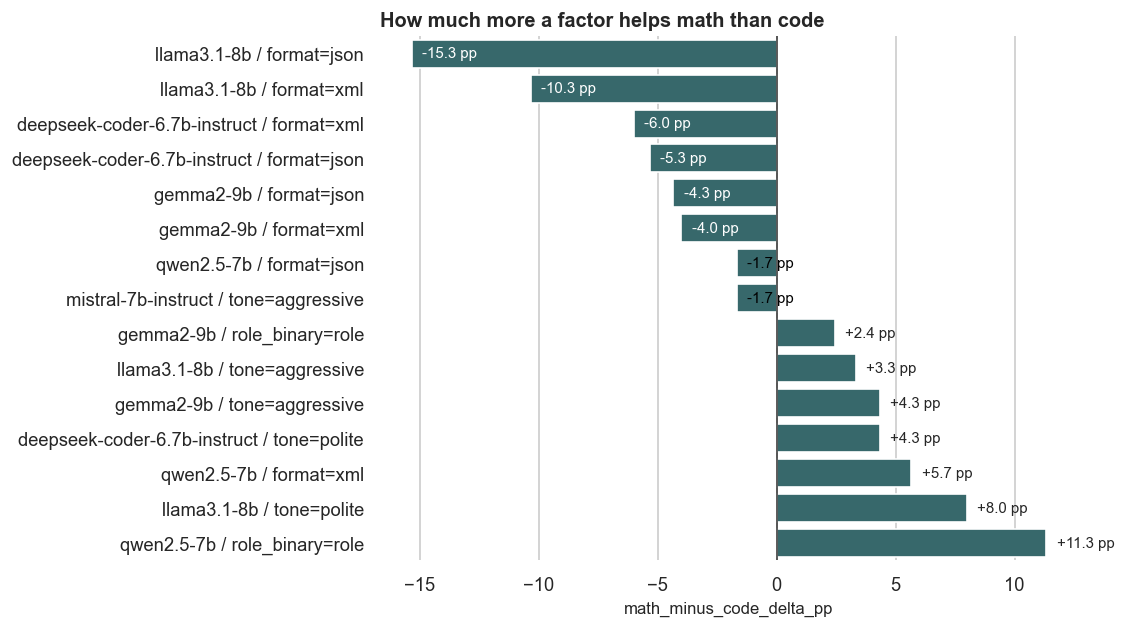

In [11]:

wide = model_contrasts.pivot_table(index=['model_short','factor','level'], columns='kind', values='delta_pp').reset_index()
if {'math','code'}.issubset(wide.columns):
    wide['math_minus_code_delta_pp'] = wide['math'] - wide['code']
    wide = wide.sort_values('math_minus_code_delta_pp', key=lambda s: s.abs(), ascending=False)
    wide['label'] = wide['model_short'] + ' / ' + wide['factor'] + '=' + wide['level']
    display(wide.rename(columns={'code':'code_delta_pp','math':'math_delta_pp'}).head(30))
    hbar(wide.head(15).sort_values('math_minus_code_delta_pp'), 'math_minus_code_delta_pp', 'label', 'How much more a factor helps math than code', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.36)


## 9. Error And Response Modes

,kind,error_category,n,kind_n,rate_within_kind,label
1,code,name_not_defined,2234,4500,0.496444,code / name_not_defined
3,code,wrong_answer,1755,4500,0.390000,code / wrong_answer
0,code,invalid_python,164,4500,0.036444,code / invalid_python
2,code,timeout,60,4500,0.013333,code / timeout
4,math,wrong_answer,3642,4500,0.809333,math / wrong_answer


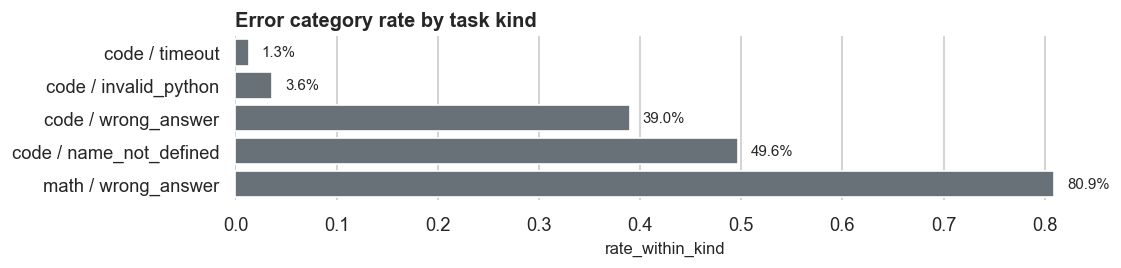

In [12]:

def classify_error(row):
    if row['passed']:
        return 'none'
    if row['empty_response']:
        return 'missing_or_empty_code' if row['kind'] == 'code' else 'empty_response'
    errors = ' '.join(map(str, row.get('errors') or [])).lower()
    if 'not valid python' in errors or 'syntaxerror' in errors:
        return 'invalid_python'
    if 'nameerror' in errors or 'is not defined' in errors:
        return 'name_not_defined'
    if 'timeout' in errors or 'timed out' in errors:
        return 'timeout'
    if 'importerror' in errors or 'modulenotfound' in errors:
        return 'import_error'
    return 'wrong_answer'

df['error_category'] = df.apply(classify_error, axis=1)
err = df[df.error_category.ne('none')].groupby(['kind','error_category']).size().reset_index(name='n')
err = err.merge(df.groupby('kind').size().rename('kind_n'), on='kind')
err['rate_within_kind'] = err.n / err.kind_n
err['label'] = err['kind'] + ' / ' + err['error_category']
display(err.sort_values(['kind','n'], ascending=[True,False]))
hbar(err.sort_values('rate_within_kind'), 'rate_within_kind', 'label', 'Error category rate by task kind', color='#67717a', height_per_row=.36)


## 10. Filtered Dataset Check

,dataset,kind,n,passed,pass_rate,mean_completion_tokens,median_duration_seconds
0,without_nemotron,code,4500,287,0.063778,348.491778,8.743776
1,without_nemotron,math,4500,858,0.190667,130.187111,0.987497


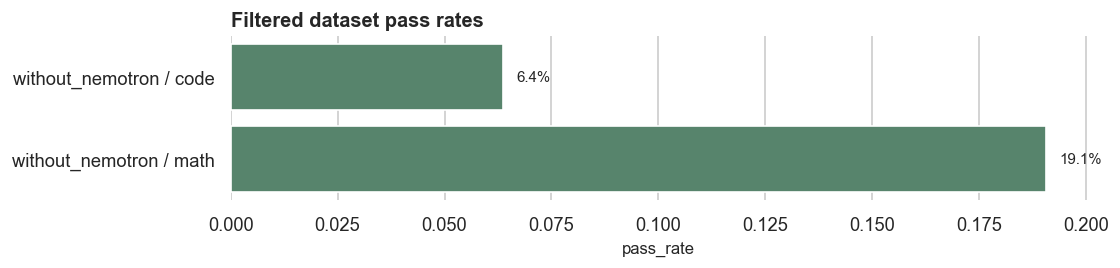

In [13]:

compare = []
for kind_name, items in df.groupby('kind'):
    compare.append({'dataset':'without_nemotron', 'kind':kind_name, 'n':len(items), 'passed':items.passed.sum(), 'pass_rate':items.passed.mean(), 'mean_completion_tokens':items.completion_tokens.mean(), 'median_duration_seconds':items.duration_seconds.median()})
compare = pd.DataFrame(compare)
display(compare)
plot = compare.assign(label=compare.dataset + ' / ' + compare.kind).sort_values('pass_rate')
hbar(plot, 'pass_rate', 'label', 'Filtered dataset pass rates', color='#4f8c6b')


## 11. Hardest/Easiest Tasks And Any-Variant Solved

In [14]:

base = df.groupby(['kind','base_task_id']).agg(n=('passed','size'), pass_rate=('passed','mean')).reset_index()
models_solved = df[df.passed].groupby(['kind','base_task_id'])['model_short'].nunique().rename('models_solved')
base = base.merge(models_solved, on=['kind','base_task_id'], how='left').fillna({'models_solved':0})
display(Markdown('**Hardest base tasks**'))
display(base.sort_values(['kind','pass_rate','models_solved']).groupby('kind').head(10))
display(Markdown('**Easiest base tasks**'))
display(base.sort_values(['kind','pass_rate','models_solved'], ascending=[True,False,False]).groupby('kind').head(10))
any_variant = (df.groupby(['kind','model_short','base_task_id'])['passed'].any().reset_index()
    .groupby(['kind','model_short']).agg(base_tasks=('base_task_id','size'), solved_by_any_variant=('passed','sum'))
    .assign(any_variant_rate=lambda x: x.solved_by_any_variant/x.base_tasks)
    .reset_index())
display(any_variant.sort_values(['kind','any_variant_rate'], ascending=[True,False]))


**Hardest base tasks**

,kind,base_task_id,n,pass_rate,models_solved
1,code,10,90,0.000000,0.0
3,code,12,90,0.000000,0.0
10,code,19,90,0.000000,0.0
11,code,2,90,0.000000,0.0
12,code,20,90,0.000000,0.0
14,code,22,90,0.000000,0.0
15,code,23,90,0.000000,0.0
16,code,24,90,0.000000,0.0
17,code,25,90,0.000000,0.0
22,code,3,90,0.000000,0.0


**Easiest base tasks**

,kind,base_task_id,n,pass_rate,models_solved
39,code,45,90,0.400000,4.0
6,code,15,90,0.277778,4.0
32,code,39,90,0.277778,3.0
2,code,11,90,0.266667,2.0
7,code,16,90,0.244444,2.0
40,code,46,90,0.211111,3.0
48,code,8,90,0.200000,3.0
8,code,17,90,0.166667,3.0
4,code,13,90,0.166667,2.0
44,code,5,90,0.166667,2.0


,kind,model_short,base_tasks,solved_by_any_variant,any_variant_rate
4,code,qwen2.5-7b,50,21,0.42
2,code,llama3.1-8b,50,15,0.30
1,code,gemma2-9b,50,14,0.28
3,code,mistral-7b-instruct,50,4,0.08
0,code,deepseek-coder-6.7b-instruct,50,3,0.06
7,math,llama3.1-8b,50,44,0.88
5,math,deepseek-coder-6.7b-instruct,50,21,0.42
9,math,qwen2.5-7b,50,21,0.42
6,math,gemma2-9b,50,15,0.30
8,math,mistral-7b-instruct,50,13,0.26


## 12. Token/Duration Correlations

In [15]:

corr_rows = []
for (kind_name, model), sub in df.groupby(['kind','model_short']):
    if sub.passed.nunique() > 1:
        corr_rows.append({'kind':kind_name, 'model_short':model, 'completion_vs_pass_corr':sub.completion_tokens.corr(sub.passed.astype(float)), 'duration_vs_pass_corr':sub.duration_seconds.corr(sub.passed.astype(float))})
corr = pd.DataFrame(corr_rows)
display(corr.sort_values(['kind','model_short']))


,kind,model_short,completion_vs_pass_corr,duration_vs_pass_corr
0,code,deepseek-coder-6.7b-instruct,-0.083195,-0.079870
1,code,gemma2-9b,-0.046950,-0.045398
2,code,llama3.1-8b,-0.027786,-0.028188
3,code,mistral-7b-instruct,-0.029555,-0.029032
4,code,qwen2.5-7b,-0.055717,-0.057262
5,math,deepseek-coder-6.7b-instruct,-0.051855,-0.028017
6,math,gemma2-9b,0.119661,-0.027483
7,math,llama3.1-8b,-0.222978,-0.223807
8,math,mistral-7b-instruct,-0.044198,-0.045959
9,math,qwen2.5-7b,0.180068,0.116849


## 13. Pairwise Common-Task Model Comparison

,kind,model_a,model_b,common_tasks,a_pass_rate,b_pass_rate,b_minus_a_pp,both_pass,only_a,only_b,both_fail
9,code,mistral-7b-instruct,qwen2.5-7b,900,0.004444,0.132222,12.777778,1,3,118,778
3,code,deepseek-coder-6.7b-instruct,qwen2.5-7b,900,0.011111,0.132222,12.111111,0,10,119,771
0,code,deepseek-coder-6.7b-instruct,gemma2-9b,900,0.011111,0.113333,10.222222,0,10,102,788
8,code,llama3.1-8b,qwen2.5-7b,900,0.057778,0.132222,7.444444,26,26,93,755
1,code,deepseek-coder-6.7b-instruct,llama3.1-8b,900,0.011111,0.057778,4.666667,2,8,50,840
6,code,gemma2-9b,qwen2.5-7b,900,0.113333,0.132222,1.888889,29,73,90,708
2,code,deepseek-coder-6.7b-instruct,mistral-7b-instruct,900,0.011111,0.004444,-0.666667,0,10,4,886
7,code,llama3.1-8b,mistral-7b-instruct,900,0.057778,0.004444,-5.333333,1,51,3,845
4,code,gemma2-9b,llama3.1-8b,900,0.113333,0.057778,-5.555556,14,88,38,760
5,code,gemma2-9b,mistral-7b-instruct,900,0.113333,0.004444,-10.888889,2,100,2,796


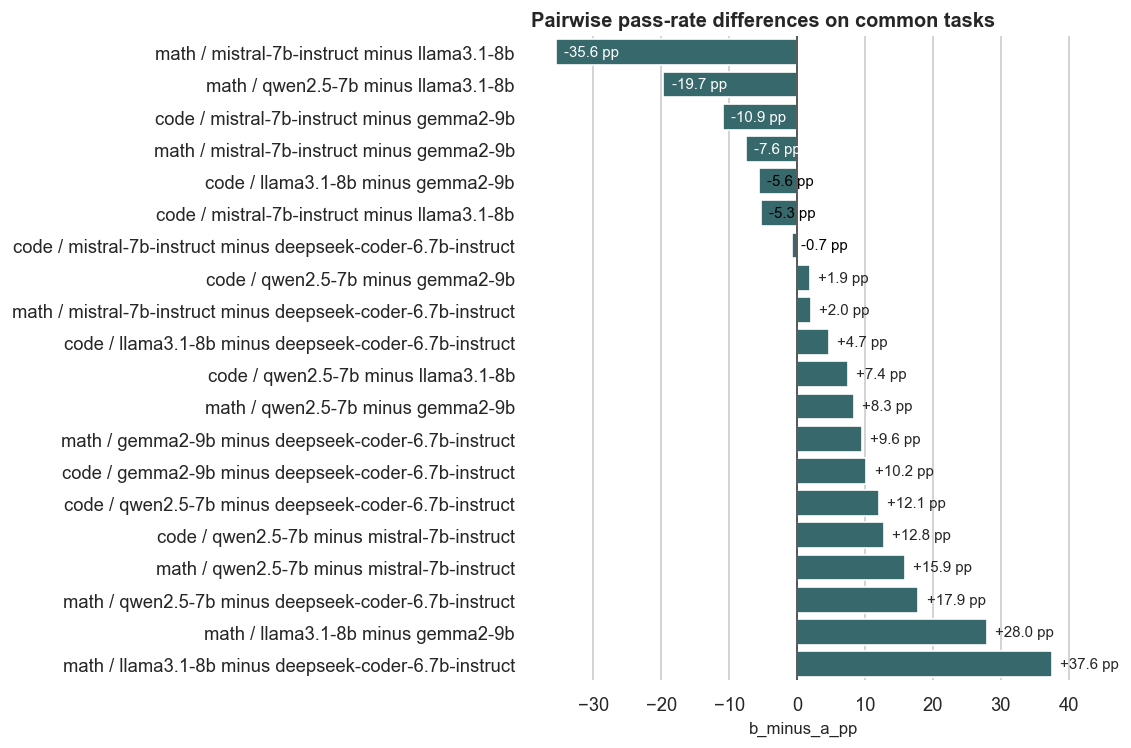

In [16]:

records = []
models = sorted(df.model_short.unique())
for kind_name, sub in df.groupby('kind'):
    for i, a in enumerate(models):
        for b in models[i+1:]:
            left = sub[sub.model_short.eq(a)].set_index('task_key')['passed']
            right = sub[sub.model_short.eq(b)].set_index('task_key')['passed']
            common = left.index.intersection(right.index)
            if len(common) == 0:
                continue
            av, bv = left.loc[common], right.loc[common]
            records.append({'kind':kind_name, 'model_a':a, 'model_b':b, 'common_tasks':len(common),
                            'a_pass_rate':av.mean(), 'b_pass_rate':bv.mean(), 'b_minus_a_pp':100*(bv.mean()-av.mean()),
                            'both_pass':int((av & bv).sum()), 'only_a':int((av & ~bv).sum()), 'only_b':int((~av & bv).sum()), 'both_fail':int((~av & ~bv).sum())})
pairwise = pd.DataFrame(records).sort_values(['kind','b_minus_a_pp'], ascending=[True,False])
display(pairwise)
plot = pairwise.copy()
plot['label'] = plot['kind'] + ' / ' + plot['model_b'] + ' minus ' + plot['model_a']
hbar(plot.sort_values('b_minus_a_pp'), 'b_minus_a_pp', 'label', 'Pairwise pass-rate differences on common tasks', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.32)


## 14. Prompt Framing Significance

In [17]:

def two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / math.sqrt(var)
    return math.erfc(z / math.sqrt(2))

def sign_p(pos, neg):
    n = pos + neg
    if n == 0:
        return 1.0
    k = min(pos, neg)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k+1)) / (2**n))

sig = []
for (kind_name, model), sub in df.groupby(['kind','model_short']):
    for factor in ['tone','role_binary','format']:
        levels = sorted(sub[factor].dropna().unique())
        for i, a in enumerate(levels):
            for b in levels[i+1:]:
                A, B = sub[sub[factor].eq(a)], sub[sub[factor].eq(b)]
                paired = []
                for _, unit in sub.groupby('base_task_id'):
                    if a in set(unit[factor]) and b in set(unit[factor]):
                        paired.append(unit[unit[factor].eq(b)].passed.mean() - unit[unit[factor].eq(a)].passed.mean())
                paired = np.array(paired)
                pos = int((paired > 0).sum()); neg = int((paired < 0).sum())
                sig.append({'kind':kind_name, 'model_short':model, 'factor':factor, 'level_a':a, 'level_b':b,
                            'n_a':len(A), 'pass_rate_a':A.passed.mean(), 'n_b':len(B), 'pass_rate_b':B.passed.mean(),
                            'delta_b_minus_a_pp':100*(B.passed.mean()-A.passed.mean()),
                            'pooled_p':two_prop_p(A.passed.sum(), len(A), B.passed.sum(), len(B)),
                            'paired_bases':len(paired), 'paired_mean_delta_pp':100*paired.mean() if len(paired) else 0,
                            'paired_positive_bases':pos, 'paired_negative_bases':neg, 'paired_sign_p':sign_p(pos, neg)})
sig = pd.DataFrame(sig)
sig['pooled_significant_0_05'] = sig.pooled_p < 0.05
sig['paired_significant_0_05'] = sig.paired_sign_p < 0.05
display(sig.sort_values(['pooled_p','paired_sign_p']).head(30))
print('Significant pooled contrasts:', int(sig.pooled_significant_0_05.sum()))
print('Significant paired sign-test contrasts:', int(sig.paired_significant_0_05.sum()))


,kind,model_short,factor,level_a,level_b,n_a,pass_rate_a,n_b,pass_rate_b,delta_b_minus_a_pp,pooled_p,paired_bases,paired_mean_delta_pp,paired_positive_bases,paired_negative_bases,paired_sign_p,pooled_significant_0_05,paired_significant_0_05
53,math,llama3.1-8b,format,json,plaintext,300,0.360000,300,0.516667,15.666667,0.000110,50,15.666667,24,8,0.007000,True,True
66,math,qwen2.5-7b,role_binary,no role,role,450,0.184444,450,0.286667,10.222222,0.000302,50,10.222222,16,2,0.001312,True,True
41,math,deepseek-coder-6.7b-instruct,format,plaintext,xml,300,0.090000,300,0.033333,-5.666667,0.003912,50,-5.666667,1,15,0.000519,True,True
37,math,deepseek-coder-6.7b-instruct,tone,neutral,polite,300,0.033333,300,0.080000,4.666667,0.013434,50,4.666667,13,2,0.007385,True,True
55,math,llama3.1-8b,format,plaintext,xml,300,0.516667,300,0.420000,-9.666667,0.017663,50,-9.666667,8,20,0.035698,True,True
0,code,deepseek-coder-6.7b-instruct,tone,aggressive,neutral,300,0.023333,300,0.003333,-2.000000,0.032712,50,-2.000000,0,3,0.250000,True,False
39,math,deepseek-coder-6.7b-instruct,format,json,plaintext,300,0.046667,300,0.090000,4.333333,0.035431,50,4.333333,15,5,0.041389,True,True
3,code,deepseek-coder-6.7b-instruct,role_binary,no role,role,450,0.017778,450,0.004444,-1.333333,0.056392,50,-1.333333,0,2,0.500000,False,False
68,math,qwen2.5-7b,format,json,xml,300,0.210000,300,0.276667,6.666667,0.057062,50,6.666667,12,3,0.035156,False,True
46,math,gemma2-9b,format,json,plaintext,300,0.130000,300,0.183333,5.333333,0.072330,50,5.333333,8,2,0.109375,False,False


Significant pooled contrasts: 7
Significant paired sign-test contrasts: 8


## 15. Behavioral Metrics From Deep Analysis

,kind,tone,passed,tests_fraction,completion_tokens,duration_seconds,response_chars,code_chars,likely_code_only,extraction_failed,runtime_failure,extra_text_ratio
0,code,aggressive,0.065333,0.107048,330.740000,8.843357,1124.017333,830.137333,0.707333,0.0,0.934667,0.208031
1,code,neutral,0.066000,0.108381,332.635333,8.835022,1124.168667,811.229333,0.723333,0.0,0.934000,0.212811
2,code,polite,0.060000,0.096857,382.100000,10.148795,1318.218667,935.800667,0.635333,0.0,0.940000,0.244038
3,math,aggressive,0.191333,NaN,129.272667,3.649675,408.740667,0.000000,0.000000,1.0,0.808667,1.000000
4,math,neutral,0.178667,NaN,120.491333,3.305704,380.812000,0.000000,0.000000,1.0,0.821333,1.000000
5,math,polite,0.202000,NaN,140.797333,3.966922,439.581333,0.000000,0.000000,1.0,0.798000,1.000000


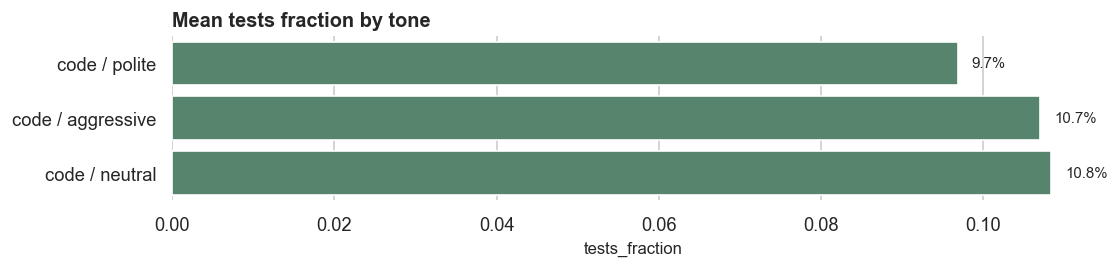

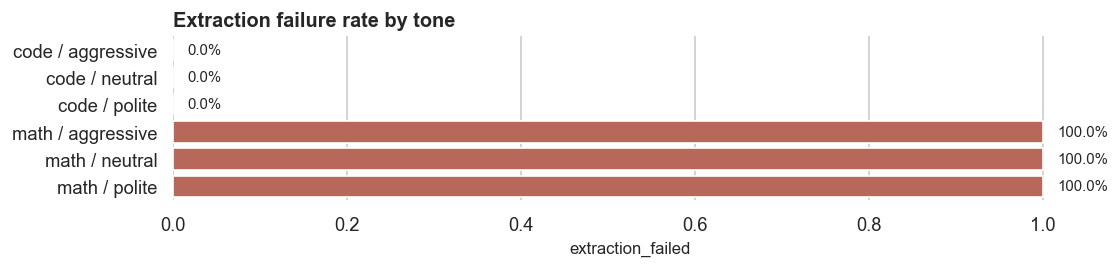

In [18]:

def safe_len(value):
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))

def count_lines(value):
    if not isinstance(value, str) or not value.strip():
        return 0
    return len(value.splitlines())

df['tests_passed_num'] = pd.to_numeric(df.get('tests_passed'), errors='coerce')
df['tests_total_num'] = pd.to_numeric(df.get('tests_total'), errors='coerce')
df['tests_fraction'] = np.where(df.tests_total_num > 0, df.tests_passed_num / df.tests_total_num, np.nan)
df['response_chars'] = df.response_text.map(safe_len)
df['code_chars'] = df.extracted_code.map(safe_len) if 'extracted_code' in df else 0
df['response_lines'] = df.response_text.map(count_lines)
df['code_lines'] = df.extracted_code.map(count_lines) if 'extracted_code' in df else 0
df['has_extracted_code'] = (df['code_chars'] > 0).astype(int)
df['extraction_failed'] = (df['has_extracted_code'] == 0).astype(int)
df['extra_text_chars'] = (df.response_chars - df.code_chars).clip(lower=0)
df['extra_text_ratio'] = np.where(df.response_chars > 0, df.extra_text_chars / df.response_chars, np.nan)
df['likely_code_only'] = ((df.has_extracted_code == 1) & (df.extra_text_ratio < .15)).astype(int)
df['runtime_failure'] = ((~df.passed) & (~df.empty_response)).astype(int)

metrics = ['passed','tests_fraction','completion_tokens','duration_seconds','response_chars','code_chars','likely_code_only','extraction_failed','runtime_failure','extra_text_ratio']
summary = df.groupby(['kind','tone'])[metrics].mean(numeric_only=True).reset_index()
display(summary)
plot = summary.assign(label=summary.kind + ' / ' + summary.tone).sort_values('tests_fraction')
hbar(plot.dropna(subset=['tests_fraction']), 'tests_fraction', 'label', 'Mean tests fraction by tone', color='#4f8c6b', height_per_row=.34)
hbar(summary.assign(label=summary.kind + ' / ' + summary.tone).sort_values('extraction_failed'), 'extraction_failed', 'label', 'Extraction failure rate by tone', color='#c75d4c', height_per_row=.34)


## 16. Code Extraction And Math Response Structure Audit

In [19]:

import ast
from fractions import Fraction

def strip_markdown_fence(text):
    if not isinstance(text, str):
        return ''
    m = re.search(r"```(?:python)?\s*(.*?)```", text, flags=re.IGNORECASE|re.DOTALL)
    return m.group(1).strip() if m else text.strip()

def raw_code_indicators(text):
    text = text if isinstance(text, str) else ''
    return {
        'has_fence': '```' in text,
        'contains_def': bool(re.search(r'\bdef\s+\w+\s*\(', text)),
        'contains_return': bool(re.search(r'\breturn\b', text)),
        'contains_import': bool(re.search(r'\bimport\s+\w+|\bfrom\s+\w+\s+import\b', text)),
    }

def parse_number_token_for_audit(token):
    token = str(token).strip().replace(',', '')
    if not token:
        return None
    is_percent = token.endswith('%')
    token = token.rstrip('%').strip()
    try:
        value = float(Fraction(re.sub(r'\s+', '', token))) if '/' in token else float(token)
    except Exception:
        return None
    return value / 100 if is_percent else value

def all_numeric_values_for_audit(text):
    text = text if isinstance(text, str) else ''
    values = []
    pattern = re.compile(r'[-+]?(?:\d+\s*/\s*\d+|\d+(?:\.\d+)?|\.\d+)\s*%?')
    for match in pattern.finditer(text):
        value = parse_number_token_for_audit(match.group(0))
        if value is not None:
            values.append({'token': match.group(0).strip(), 'value': value, 'position': match.start()})
    return values

def close_num(a, b, tol=1e-6):
    try:
        return math.isclose(float(a), float(b), rel_tol=tol, abs_tol=tol)
    except Exception:
        return False

# Code rows: inspect extraction failures using Python syntax parsing.
code_rows = []
code_subset = df[df.kind.eq('code') & df.extraction_failed.eq(1)].copy()
for _, row in code_subset.iterrows():
    response = row.get('response_text') or ''
    candidate = strip_markdown_fence(response)
    syntax_ok = False
    functions = []
    syntax_error = ''
    try:
        tree = ast.parse(candidate)
        syntax_ok = True
        functions = [n.name for n in ast.walk(tree) if isinstance(n, ast.FunctionDef)]
    except SyntaxError as exc:
        syntax_error = f'{exc.__class__.__name__}: {exc.msg}'
    indicators = raw_code_indicators(response)
    code_rows.append({'kind':row.kind, 'model_short':row.model_short, 'task_id':row.task_id, 'response_chars':len(response), 'candidate_chars':len(candidate), 'syntax_ok':syntax_ok, 'defined_functions':';'.join(functions), 'syntax_error':syntax_error, **indicators})
code_audit = pd.DataFrame(code_rows)

display(Markdown('**Code extraction audit: only code tasks are parsed as Python.**'))
if code_audit.empty:
    display(pd.DataFrame({'status':['No code extraction failures to audit']}))
else:
    display(code_audit.groupby(['kind','model_short']).agg(failures=('task_id','size'), syntax_ok_rate=('syntax_ok','mean'), raw_has_def=('contains_def','mean'), raw_has_return=('contains_return','mean'), median_response_chars=('response_chars','median')).reset_index())
    display(code_audit.sort_values('response_chars', ascending=False).head(20))

# Math rows: inspect numeric extraction behavior instead of Python syntax.
math_subset = df[df.kind.eq('math')].copy()
math_rows = []
for _, row in math_subset.iterrows():
    response = row.get('response_text') or ''
    expected = row.get('expected_answer', np.nan)
    stored_values = row.get('extracted_values') if isinstance(row.get('extracted_values'), list) else []
    all_values = all_numeric_values_for_audit(response)
    expected_anywhere = any(close_num(v['value'], expected) for v in all_values)
    stored_expected = any(close_num(v, expected) for v in stored_values)
    first_expected = next((v for v in all_values if close_num(v['value'], expected)), None)
    math_rows.append({
        'model_short': row.model_short,
        'task_id': row.task_id,
        'passed': bool(row.passed),
        'expected_answer': expected,
        'stored_extracted_values': stored_values,
        'numeric_tokens_found': len(all_values),
        'expected_appears_anywhere': expected_anywhere,
        'stored_extraction_contains_expected': stored_expected,
        'possible_extractor_false_negative': (not bool(row.passed)) and expected_anywhere and not stored_expected,
        'response_chars': len(response),
        'first_expected_token': first_expected['token'] if first_expected else '',
    })
math_audit = pd.DataFrame(math_rows)

display(Markdown('**Math response audit: numeric extraction and possible evaluator false negatives.**'))
summary = math_audit.groupby('model_short').agg(
    rows=('task_id','size'),
    failed=('passed', lambda s: int((~s).sum())),
    no_numeric_tokens=('numeric_tokens_found', lambda s: int((s == 0).sum())),
    expected_anywhere_rate=('expected_appears_anywhere','mean'),
    possible_extractor_false_negatives=('possible_extractor_false_negative','sum'),
    median_response_chars=('response_chars','median'),
).reset_index()
display(summary)
possible = math_audit[math_audit.possible_extractor_false_negative].sort_values(['model_short','response_chars'], ascending=[True,False])
if possible.empty:
    display(pd.DataFrame({'status':['No possible math extractor false negatives found']}))
else:
    display(possible[['model_short','task_id','expected_answer','stored_extracted_values','numeric_tokens_found','first_expected_token','response_chars']].head(30))


**Code extraction audit: only code tasks are parsed as Python.**

,status
0,No code extraction failures to audit


**Math response audit: numeric extraction and possible evaluator false negatives.**

,model_short,rows,failed,no_numeric_tokens,expected_anywhere_rate,possible_extractor_false_negatives,median_response_chars
0,deepseek-coder-6.7b-instruct,900,849,24,0.116667,54,917.0
1,gemma2-9b,900,763,0,0.166667,13,6.0
2,llama3.1-8b,900,511,0,0.467778,64,511.0
3,mistral-7b-instruct,900,831,0,0.108889,29,56.0
4,qwen2.5-7b,900,688,0,0.146667,0,3.0


,model_short,task_id,expected_answer,stored_extracted_values,numeric_tokens_found,first_expected_token,response_chars
669,deepseek-coder-6.7b-instruct,math_038_4,4.000000,[-1.0],45,4,1693
719,deepseek-coder-6.7b-instruct,math_040_18,0.333333,[3.0],38,1/3,1612
658,deepseek-coder-6.7b-instruct,math_037_11,10.000000,[5000.0],34,10,1539
397,deepseek-coder-6.7b-instruct,math_023_2,0.360000,[2.0],31,9/25,1434
673,deepseek-coder-6.7b-instruct,math_038_8,4.000000,[0.0],54,4,1419
283,deepseek-coder-6.7b-instruct,math_016_14,0.333333,[3.0],38,4/12,1316
645,deepseek-coder-6.7b-instruct,math_036_16,0.333333,[0.33],32,2/6,1291
497,deepseek-coder-6.7b-instruct,math_028_12,40.000000,[10.0],29,40,1251
3,deepseek-coder-6.7b-instruct,math_001_4,12.000000,[9.0],20,12,1233
83,deepseek-coder-6.7b-instruct,math_005_12,3.000000,[3.3166247903554],18,3,1224


## 17. Difficulty-Band Prompt Effects

,kind,difficulty_band,tone,n,pass_rate,tests_fraction,mean_completion_tokens,median_duration
0,code,hard,aggressive,510,0.000000,0.002521,306.915686,7.714353
1,code,hard,neutral,510,0.001961,0.003081,302.609804,7.715686
2,code,hard,polite,510,0.000000,0.003081,369.766667,9.300471
3,code,medium,aggressive,480,0.022917,0.065774,360.050000,9.082628
4,code,medium,neutral,480,0.022917,0.071429,365.737500,9.234534
5,code,medium,polite,480,0.031250,0.066369,398.679167,10.487021
6,code,easy,aggressive,510,0.170588,0.250420,326.978431,8.027259
7,code,easy,neutral,510,0.170588,0.248459,331.505882,8.004244
8,code,easy,polite,510,0.147059,0.219328,378.829412,9.668745
9,math,hard,aggressive,510,0.023529,NaN,172.094118,1.073596


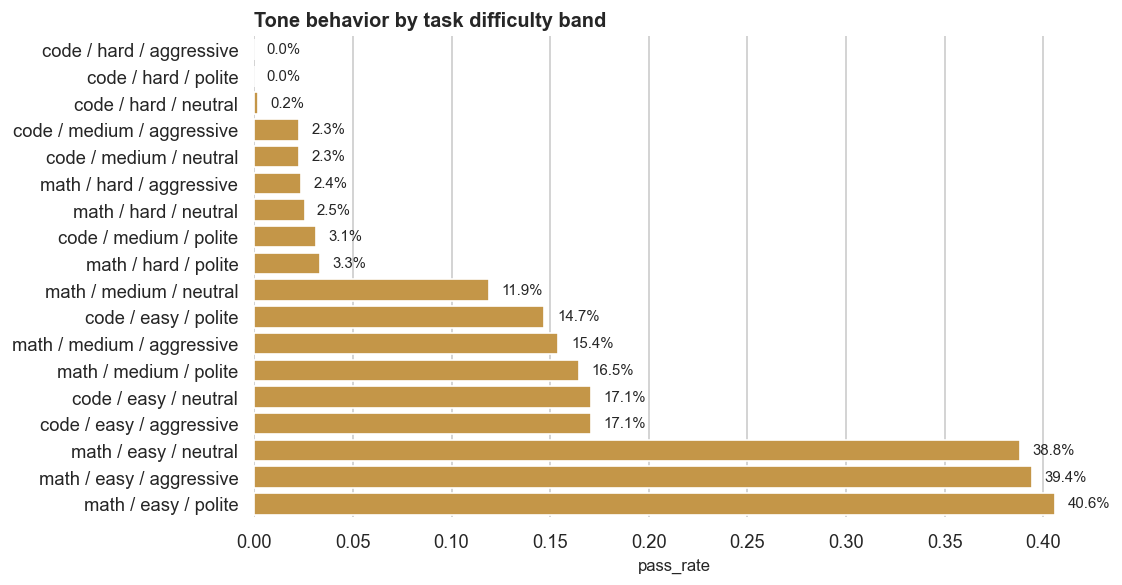

In [20]:

base_perf = df.groupby(['kind','base_task_id']).agg(base_pass_rate=('passed','mean'), base_tests_fraction=('tests_fraction','mean')).reset_index()
base_perf['difficulty_source'] = base_perf.base_tests_fraction.fillna(base_perf.base_pass_rate)
parts = []
for kind_name, sub in base_perf.groupby('kind'):
    tmp = sub.copy()
    tmp['difficulty_band'] = pd.qcut(tmp.difficulty_source.rank(method='first'), q=3, labels=['hard','medium','easy'])
    parts.append(tmp[['kind','base_task_id','difficulty_band']])
difficulty = pd.concat(parts, ignore_index=True)
df = df.merge(difficulty, on=['kind','base_task_id'], how='left', suffixes=('', '_new'))
if 'difficulty_band_new' in df:
    df['difficulty_band'] = df['difficulty_band'].fillna(df['difficulty_band_new'])
    df = df.drop(columns=['difficulty_band_new'])

diff_tone = df.groupby(['kind','difficulty_band','tone'], observed=False).agg(n=('passed','size'), pass_rate=('passed','mean'), tests_fraction=('tests_fraction','mean'), mean_completion_tokens=('completion_tokens','mean'), median_duration=('duration_seconds','median')).reset_index()
display(diff_tone)
plot = diff_tone.assign(label=diff_tone.kind.astype(str)+' / '+diff_tone.difficulty_band.astype(str)+' / '+diff_tone.tone.astype(str)).sort_values('pass_rate')
hbar(plot, 'pass_rate', 'label', 'Tone behavior by task difficulty band', color='#d89b34', height_per_row=.28)


## 18. Behavior-Control Models

In [21]:

def fit_lpm(data, outcome, controls):
    work = data[[outcome,'tone','role_binary','format','model_short','kind','base_task_id', *controls]].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return pd.DataFrame(), 0
    y = work[outcome].astype(float).to_numpy()
    X = pd.get_dummies(work[['tone','role_binary','format','model_short','kind','base_task_id', *controls]], drop_first=True, dtype=float)
    X.insert(0, 'Intercept', 1.0)
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
    pred = X.to_numpy() @ beta
    resid = y - pred
    dof = max(len(y) - X.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(X.to_numpy().T @ X.to_numpy())
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))
    out = pd.DataFrame({'term':X.columns, 'coef':beta, 'std_err':se, 'abs_coef':np.abs(beta), 'nobs':len(y)})
    return out, len(y)

df['passed_float'] = df.passed.astype(float)
df['log_completion_tokens'] = np.log1p(df.completion_tokens)
df['log_duration_seconds'] = np.log1p(df.duration_seconds)
control_sets = {
    'M0_prompt_model_task_fe': [],
    'M1_length': ['log_completion_tokens'],
    'M2_response_shape': ['likely_code_only','extraction_failed'],
    'M3_runtime': ['log_duration_seconds'],
    'M4_all_behavior_controls': ['log_completion_tokens','likely_code_only','extraction_failed','log_duration_seconds'],
}
rows=[]
for outcome in ['passed_float','tests_fraction']:
    for spec, controls in control_sets.items():
        res, nobs = fit_lpm(df, outcome, controls)
        if not res.empty:
            res['outcome'] = outcome
            res['model_spec'] = spec
            rows.append(res)
control_models = pd.concat(rows, ignore_index=True)
focus = control_models[control_models.term.str.contains('tone_|role_binary_|format_|log_completion|likely_code_only|extraction_failed|log_duration', regex=True)].copy()
display(focus.sort_values(['outcome','model_spec','term'])[['outcome','model_spec','term','coef','std_err','nobs']])


,outcome,model_spec,term,coef,std_err,nobs
4,passed_float,M0_prompt_model_task_fe,format_plaintext,0.026000,0.007324,9000
5,passed_float,M0_prompt_model_task_fe,format_xml,0.014667,0.007324,9000
3,passed_float,M0_prompt_model_task_fe,role_binary_role,0.007333,0.005980,9000
1,passed_float,M0_prompt_model_task_fe,tone_neutral,-0.006000,0.007324,9000
2,passed_float,M0_prompt_model_task_fe,tone_polite,0.002667,0.007324,9000
...,...,...,...,...,...,...
799,tests_fraction,M4_all_behavior_controls,log_completion_tokens,-0.062479,0.079099,4500
802,tests_fraction,M4_all_behavior_controls,log_duration_seconds,0.022739,0.099701,4500
805,tests_fraction,M4_all_behavior_controls,role_binary_role,-0.010632,0.007111,4500
803,tests_fraction,M4_all_behavior_controls,tone_neutral,0.001752,0.008701,4500


## 19. Pooled Prompt Sensitivity And Behavior Controls

**Raw pooled prompt sensitivity across all task kinds**

,group,factor,baseline,level,baseline_n,n,baseline_pass_rate,pass_rate,delta_pp,p_value,completion_delta,duration_delta
3,all_task_kinds,format,plaintext,json,3000,3000,0.139667,0.113667,-2.600000,0.002465,-25.066667,-0.701202
4,all_task_kinds,format,plaintext,xml,3000,3000,0.139667,0.128333,-1.133333,0.197564,-5.319000,-0.154271
2,all_task_kinds,role_binary,no role,role,4500,4500,0.123556,0.130889,0.733333,0.296531,10.416222,0.277569
0,all_task_kinds,tone,neutral,aggressive,3000,3000,0.122333,0.128333,0.600000,0.482775,3.443000,0.176153
1,all_task_kinds,tone,neutral,polite,3000,3000,0.122333,0.131000,0.866667,0.312880,34.885333,0.987496


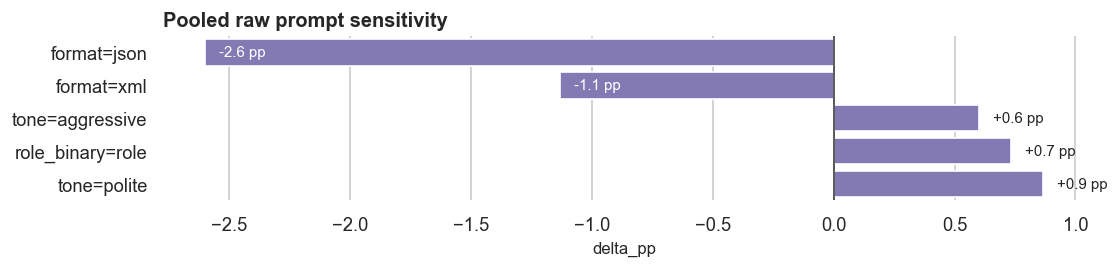

**Behavior-controlled pooled prompt sensitivity**

,group,term,coef_pp,std_err_pp,p_value,nobs,controls,fixed_effects
6,all_task_kinds,log_completion_tokens,12.011112,0.877153,1.113498e-42,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
7,all_task_kinds,log_duration_seconds,-19.383383,1.806535,7.391983e-27,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
8,all_task_kinds,extraction_failed,10.575332,1.516311,3.072135e-12,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
4,all_task_kinds,format_json_vs_plaintext,-2.546662,0.726337,4.546021e-04,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
2,all_task_kinds,tone_polite_vs_neutral,1.271358,0.730167,8.165088e-02,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
5,all_task_kinds,format_xml_vs_plaintext,-1.184676,0.724148,1.018484e-01,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
1,all_task_kinds,tone_aggressive_vs_neutral,0.753491,0.724367,2.982438e-01,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"
3,all_task_kinds,role_vs_no_role,0.609492,0.591548,3.028525e-01,9000,"log_completion_tokens, log_duration_seconds, e...","model_short, base_task_id, kind"


In [22]:

def prompt_raw_sensitivity(data, group_label='all'):
    baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
    records = []
    for factor, baseline in baselines.items():
        base = data[data[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in data.groupby(factor):
            if level == baseline:
                continue
            p_value = raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items)) if 'raw_two_prop_p' in globals() else two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            records.append({
                'group': group_label,
                'factor': factor,
                'baseline': baseline,
                'level': level,
                'baseline_n': len(base),
                'n': len(items),
                'baseline_pass_rate': base.passed.mean(),
                'pass_rate': items.passed.mean(),
                'delta_pp': 100*(items.passed.mean() - base.passed.mean()),
                'p_value': p_value,
                'completion_delta': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
    out = pd.DataFrame(records)
    return out

def prepare_behavior_frame(data):
    work = data.copy()
    work['passed_float'] = work.passed.astype(float)
    work['log_completion_tokens'] = np.log1p(pd.to_numeric(work.completion_tokens, errors='coerce').fillna(0))
    work['log_duration_seconds'] = np.log1p(pd.to_numeric(work.duration_seconds, errors='coerce').fillna(0))
    work['empty_response_control'] = work.empty_response.astype(float) if 'empty_response' in work else 0.0
    if 'extraction_failed' not in work:
        if 'extracted_code' in work:
            code_missing = work.extracted_code.fillna('').astype(str).str.strip().eq('')
            work['extraction_failed'] = np.where(work.kind.eq('code'), code_missing, False).astype(float)
        else:
            work['extraction_failed'] = 0.0
    work['extraction_failed'] = pd.to_numeric(work.extraction_failed, errors='coerce').fillna(0).astype(float)
    if 'api_error' in work:
        work['api_error_control'] = work.api_error.astype(float)
    else:
        work['api_error_control'] = 0.0
    return work

def controlled_prompt_model(data, group_label='all', include_kind=True):
    model_col = 'model_short' if 'model_short' in data.columns else 'model_slug'
    task_col = 'base_task_id' if 'base_task_id' in data.columns else 'task_id'
    work = prepare_behavior_frame(data)
    work['tone_aggressive_vs_neutral'] = work.tone.eq('aggressive').astype(float)
    work['tone_polite_vs_neutral'] = work.tone.eq('polite').astype(float)
    work['role_vs_no_role'] = work.role_binary.eq('role').astype(float)
    work['format_json_vs_plaintext'] = work.format.eq('json').astype(float)
    work['format_xml_vs_plaintext'] = work.format.eq('xml').astype(float)
    prompt_cols = ['tone_aggressive_vs_neutral','tone_polite_vs_neutral','role_vs_no_role','format_json_vs_plaintext','format_xml_vs_plaintext']
    behavior_cols = ['log_completion_tokens','log_duration_seconds','empty_response_control','extraction_failed','api_error_control']
    behavior_cols = [c for c in behavior_cols if c in work and work[c].nunique(dropna=True) > 1]
    fe_cols = [model_col, task_col] + (['kind'] if include_kind and work.kind.nunique() > 1 else [])
    needed = ['passed_float', *prompt_cols, *behavior_cols, *fe_cols]
    work = work[needed].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return pd.DataFrame()
    X = work[prompt_cols + behavior_cols].astype(float).copy()
    for col in fe_cols:
        dummies = pd.get_dummies(work[col].astype(str), prefix=col, drop_first=True, dtype=float)
        X = pd.concat([X, dummies], axis=1)
    X.insert(0, 'Intercept', 1.0)
    y = work.passed_float.to_numpy(dtype=float)
    Xv = X.to_numpy(dtype=float)
    beta, *_ = np.linalg.lstsq(Xv, y, rcond=None)
    pred = Xv @ beta
    resid = y - pred
    dof = max(len(y) - Xv.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(Xv.T @ Xv)
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))
    rows = pd.DataFrame({'term':X.columns, 'coef':beta, 'std_err':se})
    rows = rows[rows.term.isin(prompt_cols + behavior_cols)].copy()
    rows['group'] = group_label
    rows['coef_pp'] = 100 * rows.coef
    rows['std_err_pp'] = 100 * rows.std_err
    rows['p_value'] = [math.erfc(abs(c/s) / math.sqrt(2)) if s > 0 else 1.0 for c, s in zip(rows.coef, rows.std_err)]
    rows['nobs'] = len(y)
    rows['controls'] = ', '.join(behavior_cols) if behavior_cols else 'none'
    rows['fixed_effects'] = ', '.join(fe_cols)
    return rows[['group','term','coef_pp','std_err_pp','p_value','nobs','controls','fixed_effects']]

pooled_raw = prompt_raw_sensitivity(df, 'all_task_kinds')
display(Markdown('**Raw pooled prompt sensitivity across all task kinds**'))
display(pooled_raw.sort_values(['factor','level']))
if not pooled_raw.empty:
    pooled_raw_plot = pooled_raw.assign(label=pooled_raw.factor + '=' + pooled_raw.level).sort_values('delta_pp')
    hbar(pooled_raw_plot, 'delta_pp', 'label', 'Pooled raw prompt sensitivity', fmt='{:+.1f} pp', color='#7c6fbd', xline=0, height_per_row=.36)

pooled_controlled = controlled_prompt_model(df, 'all_task_kinds', include_kind=True)
display(Markdown('**Behavior-controlled pooled prompt sensitivity**'))
display(pooled_controlled.sort_values('p_value'))


## 20. Task-Kind Prompt Sensitivity And Behavior Controls

**Raw prompt sensitivity by task kind**

,group,factor,baseline,level,baseline_n,n,baseline_pass_rate,pass_rate,delta_pp,p_value,completion_delta,duration_delta
3,code,format,plaintext,json,1500,1500,0.062667,0.063333,0.066667,0.940099,-13.912000,-0.325598
4,code,format,plaintext,xml,1500,1500,0.062667,0.065333,0.266667,0.765412,-12.476667,-0.281672
2,code,role_binary,no role,role,2250,2250,0.068444,0.059111,-0.933333,0.200152,8.782667,0.218898
0,code,tone,neutral,aggressive,1500,1500,0.066000,0.065333,-0.066667,0.941243,-1.895333,0.008335
1,code,tone,neutral,polite,1500,1500,0.066000,0.060000,-0.600000,0.498848,49.464667,1.313774
8,math,format,plaintext,json,1500,1500,0.216667,0.164000,-5.266667,0.000239,-36.221333,-1.076805
9,math,format,plaintext,xml,1500,1500,0.216667,0.191333,-2.533333,0.085128,1.838667,-0.026871
7,math,role_binary,no role,role,2250,2250,0.178667,0.202667,2.400000,0.040442,12.049778,0.336241
5,math,tone,neutral,aggressive,1500,1500,0.178667,0.191333,1.266667,0.371662,8.781333,0.343971
6,math,tone,neutral,polite,1500,1500,0.178667,0.202000,2.333333,0.103571,20.306000,0.661217


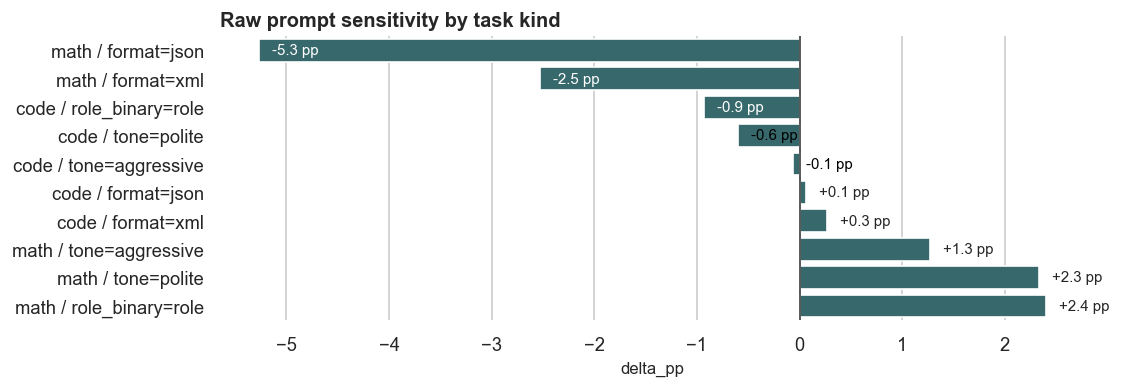

**Behavior-controlled prompt sensitivity by task kind**

,group,term,coef_pp,std_err_pp,p_value,nobs,controls,fixed_effects
5,code,log_completion_tokens,-25.951453,7.217010,3.233051e-04,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
6,code,log_duration_seconds,27.120698,9.083981,2.830670e-03,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
2,code,role_vs_no_role,-0.847295,0.651702,1.935576e-01,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
1,code,tone_polite_vs_neutral,-0.096522,0.819308,9.062189e-01,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
3,code,format_json_vs_plaintext,-0.061520,0.798388,9.385799e-01,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
0,code,tone_aggressive_vs_neutral,-0.059636,0.797160,9.403653e-01,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
4,code,format_xml_vs_plaintext,0.029175,0.798630,9.708584e-01,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
12,math,log_completion_tokens,20.934877,1.619552,3.196902e-38,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
13,math,log_duration_seconds,-33.140913,2.903083,3.488193e-30,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"
10,math,format_json_vs_plaintext,-4.726235,1.168711,5.255337e-05,4500,"log_completion_tokens, log_duration_seconds","model_short, base_task_id"


In [23]:

raw_parts = []
controlled_parts = []
for kind_name, sub in df.groupby('kind'):
    raw_parts.append(prompt_raw_sensitivity(sub, kind_name))
    controlled_parts.append(controlled_prompt_model(sub, kind_name, include_kind=False))

kind_raw = pd.concat(raw_parts, ignore_index=True) if raw_parts else pd.DataFrame()
kind_controlled = pd.concat(controlled_parts, ignore_index=True) if controlled_parts else pd.DataFrame()

display(Markdown('**Raw prompt sensitivity by task kind**'))
display(kind_raw.sort_values(['group','factor','level']))
if not kind_raw.empty:
    plot = kind_raw.assign(label=kind_raw.group + ' / ' + kind_raw.factor + '=' + kind_raw.level).sort_values('delta_pp')
    hbar(plot, 'delta_pp', 'label', 'Raw prompt sensitivity by task kind', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.34)

display(Markdown('**Behavior-controlled prompt sensitivity by task kind**'))
display(kind_controlled.sort_values(['group','p_value']))
